# Fuel prices in Wildau before and after the 12:00 rule

Since **1 April 2026** fuel stations in Germany may raise their prices only once a day, at 12:00.
This notebook looks at what that changed at two stations in Wildau (Brandenburg):
**Shell, Richard-Sorge-Str. 30** and **Sprint, Chausseestr. 1**, from 1 Nov 2025 to 31 Oct 2026.

Only **real prices** are used here (Tankerkönig / MTS-K, CC BY-NC-SA 4.0). The simulated sales
from the database are deliberately left out: anything found in them would only reflect the rules
of the generator.

Questions:
1. Did price increases move to 12:00? (does the rule hold at these stations)
2. Did the gap between the most expensive and the cheapest hour of the day change?
3. Is Sprint cheaper than Shell?

The input `data/prices.csv` is produced by `src/tk_download.py` and `src/tk_clean.py`. It is not in
the repository because Tankerkönig data may not be redistributed.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

TZ = "Europe/Berlin"
REFORM_DAY = pd.Timestamp("2026-04-01").date()
PERIOD_START_UTC = pd.Timestamp("2025-10-31 23:00")   # 1 Nov 2025 00:00 in Berlin
PERIOD_END_UTC = pd.Timestamp("2026-10-31 23:00")     # 1 Nov 2026 00:00 in Berlin
COLORS = {"before": "#9e9e9e", "after": "#3949ab"}    # same colours as in the Power BI report

DATA = Path("../data")
IMG = Path("../docs/img")
IMG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 1. The data

In [2]:
prices = pd.read_csv(DATA / "prices.csv", parse_dates=["valid_from_utc"])
prices = prices.sort_values(["station", "fuel", "valid_from_utc"]).reset_index(drop=True)

local = prices["valid_from_utc"].dt.tz_localize("UTC").dt.tz_convert(TZ)
prices["local_date"] = local.dt.date
prices["local_hour"] = local.dt.hour
prices["period"] = np.where(prices["local_date"] >= REFORM_DAY, "after", "before")
prices["change_ct"] = prices.groupby(["station", "fuel"])["price_eur"].diff() * 100

print(f"{len(prices):,} price changes, {prices['valid_from_utc'].min():%Y-%m-%d} to {prices['valid_from_utc'].max():%Y-%m-%d}")
per_day = (prices.groupby(["station", "period"])["local_date"].agg(["size", "nunique"])
           .assign(changes_per_day=lambda d: (d["size"] / d["nunique"] / 3).round(1)))
per_day[["changes_per_day"]]  # per fuel and day

49,028 price changes, 2025-10-31 to 2026-10-31


changes_per_day
station period                 
shell   after              11.7
        before             33.7
sprint  after              13.4
        before             38.7

Each price is valid from its timestamp until the next change. For the analysis by hour, every price
is weighted by the seconds it was valid within the hour: 1.799 EUR for 10 minutes and 1.759 EUR for
50 minutes give an hourly price of 1.766 EUR. The same logic is in the SQL view `dbo.v_hourly_price`.

In [3]:
def hourly_prices(p: pd.DataFrame) -> pd.DataFrame:
    """Time-weighted average price per station, fuel and hour (UTC)."""
    p = p[["station", "fuel", "valid_from_utc", "price_eur"]].copy()
    p["valid_to_utc"] = (p.groupby(["station", "fuel"])["valid_from_utc"].shift(-1)
                         .fillna(PERIOD_END_UTC))
    first_hour = p["valid_from_utc"].dt.floor("h")
    n_hours = np.ceil((p["valid_to_utc"] - first_hour) / pd.Timedelta(hours=1)).astype(int)

    # one row per price period and hour it touches
    rows = p.loc[p.index.repeat(n_hours)].copy()
    offset = rows.groupby(level=0).cumcount()
    rows["hour_utc"] = first_hour.loc[rows.index] + pd.to_timedelta(offset, unit="h")
    start = rows[["valid_from_utc", "hour_utc"]].max(axis=1)
    end = np.minimum(rows["valid_to_utc"], rows["hour_utc"] + pd.Timedelta(hours=1))
    rows["seconds"] = (end - start).dt.total_seconds()
    rows["price_x_seconds"] = rows["price_eur"] * rows["seconds"]

    h = (rows.groupby(["station", "fuel", "hour_utc"])[["price_x_seconds", "seconds"]].sum()
         .reset_index())
    h = h[(h["hour_utc"] >= PERIOD_START_UTC) & (h["hour_utc"] < PERIOD_END_UTC) & (h["seconds"] == 3600)]
    h["price"] = h["price_x_seconds"] / 3600

    local = h["hour_utc"].dt.tz_localize("UTC").dt.tz_convert(TZ)
    h["local_date"] = local.dt.date
    h["local_hour"] = local.dt.hour
    h["period"] = np.where(h["local_date"] >= REFORM_DAY, "after", "before")
    h["diff_ct"] = 100 * (h["price"] - h.groupby(["station", "fuel", "local_date"])["price"].transform("mean"))
    return h.drop(columns=["price_x_seconds", "seconds"]).reset_index(drop=True)


hourly = hourly_prices(prices)
print(f"{len(hourly):,} station-fuel-hours (expected 2 x 3 x 8,760 = 52,560)")

52,560 station-fuel-hours (expected 2 x 3 x 8,760 = 52,560)


## 2. Did price increases move to 12:00?

Share of all price increases that happen in the 12:00 hour (local time), before and after 1 April 2026.
A chi-square test checks whether the hour of an increase is independent of the period.

In [4]:
ups = prices[prices["change_ct"] > 0]
table = pd.crosstab(ups["period"], np.where(ups["local_hour"] == 12, "12:00-12:59", "other hours"))
table = table.loc[["before", "after"]].rename_axis(index="period", columns=None)
display(table.assign(share_at_noon=lambda t: (100 * t["12:00-12:59"] / t.sum(axis=1)).round(1)))

chi2, p_value, dof, _ = stats.chi2_contingency(table)
print(f"chi-square = {chi2:,.0f}, p = {p_value:.1e}")

,12:00-12:59,other hours,share_at_noon
period,,,
before,905,6861,11.7
after,1227,39,96.9


chi-square = 4,384, p = 0.0e+00


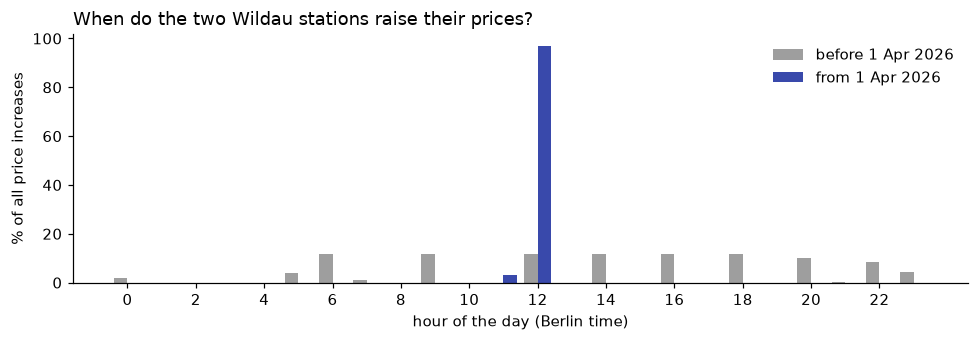

In [5]:
share = (ups.groupby(["period", "local_hour"]).size() / ups.groupby("period").size() * 100).unstack(0).fillna(0)

fig, ax = plt.subplots(figsize=(9, 3.2))
width = 0.4
ax.bar(share.index - width / 2, share["before"], width, color=COLORS["before"], label="before 1 Apr 2026")
ax.bar(share.index + width / 2, share["after"], width, color=COLORS["after"], label="from 1 Apr 2026")
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("hour of the day (Berlin time)")
ax.set_ylabel("% of all price increases")
ax.set_title("When do the two Wildau stations raise their prices?", loc="left")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(IMG / "price_increases_by_hour.png")
plt.show()

## 3. The daily price pattern and the gap between the most expensive and the cheapest hour

The pattern is shown as the difference from the same day's average, so that the overall price level
(which rose sharply in March 2026) does not hide the daily cycle.

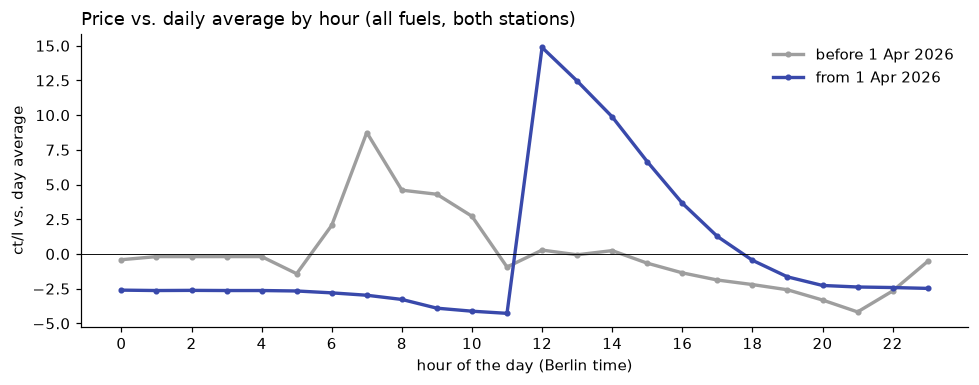

,cheapest hour,ct below average,most expensive hour,ct above average
period,,,,
before,21,-4.2,7,8.8
after,11,-4.3,12,14.9


In [6]:
pattern = hourly.groupby(["period", "local_hour"])["diff_ct"].mean().unstack(0)[["before", "after"]]

fig, ax = plt.subplots(figsize=(9, 3.6))
for period, label in [("before", "before 1 Apr 2026"), ("after", "from 1 Apr 2026")]:
    ax.plot(pattern.index, pattern[period], color=COLORS[period], lw=2.2, marker="o", ms=3, label=label)
ax.axhline(0, color="black", lw=0.6)
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("hour of the day (Berlin time)")
ax.set_ylabel("ct/l vs. day average")
ax.set_title("Price vs. daily average by hour (all fuels, both stations)", loc="left")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(IMG / "daily_pattern.png")
plt.show()

summary = pd.DataFrame({
    "cheapest hour": pattern.idxmin(),
    "ct below average": pattern.min().round(1),
    "most expensive hour": pattern.idxmax(),
    "ct above average": pattern.max().round(1),
})
summary

**Hypothesis test.** For every station, fuel and day the *daily spread* is the most expensive hour
minus the cheapest hour of that day, in cents.

- H0: the daily spread is the same before and after 1 April 2026.
- H1: the daily spread is larger after 1 April 2026.

The spreads are not normally distributed, so the one-sided Mann-Whitney U test is used instead of a
t-test. The effect is reported as the difference of the medians with a 95 % bootstrap interval.

Caveats: consecutive days are not independent (prices follow trends), so the p-value is
optimistic; and prices were much higher after March 2026, which could widen the spread on its
own. The spread is therefore also checked relative to the price level.

In [7]:
daily = (hourly.groupby(["station", "fuel", "local_date", "period"])["price"]
         .agg(high="max", low="min", mean="mean").reset_index())
daily["spread_ct"] = 100 * (daily["high"] - daily["low"])
daily["spread_pct"] = 100 * (daily["high"] - daily["low"]) / daily["mean"]

before = daily.loc[daily["period"] == "before", "spread_ct"]
after = daily.loc[daily["period"] == "after", "spread_ct"]
u, p_value = stats.mannwhitneyu(after, before, alternative="greater")

rng = np.random.default_rng(0)
boot = [np.median(rng.choice(after, after.size)) - np.median(rng.choice(before, before.size))
        for _ in range(5000)]
low, high = np.percentile(boot, [2.5, 97.5])

print(f"median daily spread before: {before.median():.1f} ct, after: {after.median():.1f} ct")
print(f"difference of medians: {after.median() - before.median():.1f} ct (95 % CI {low:.1f} to {high:.1f})")
print(f"Mann-Whitney U = {u:,.0f}, one-sided p = {p_value:.1e}")

# Robustness 1: relative to the price level
rel_before = daily.loc[daily["period"] == "before", "spread_pct"]
rel_after = daily.loc[daily["period"] == "after", "spread_pct"]
print(f"\nrelative spread (% of the day's average price): before {rel_before.median():.1f} %, "
      f"after {rel_after.median():.1f} %, one-sided p = "
      f"{stats.mannwhitneyu(rel_after, rel_before, alternative='greater').pvalue:.1e}")

# Robustness 2: per station and fuel
by_group = (daily.groupby(["station", "fuel", "period"])["spread_ct"].median().unstack()[["before", "after"]]
            .round(1))
by_group

median daily spread before: 13.9 ct, after: 20.6 ct
difference of medians: 6.7 ct (95 % CI 6.2 to 7.1)
Mann-Whitney U = 935,856, one-sided p = 8.9e-131

relative spread (% of the day's average price): before 8.1 %, after 9.8 %, one-sided p = 1.1e-34


period          before  after
station fuel                 
shell   diesel    16.8   23.4
        e10       13.9   19.4
        e5        13.9   19.4
sprint  diesel    14.7   23.1
        e10       12.9   19.6
        e5        12.9   19.6

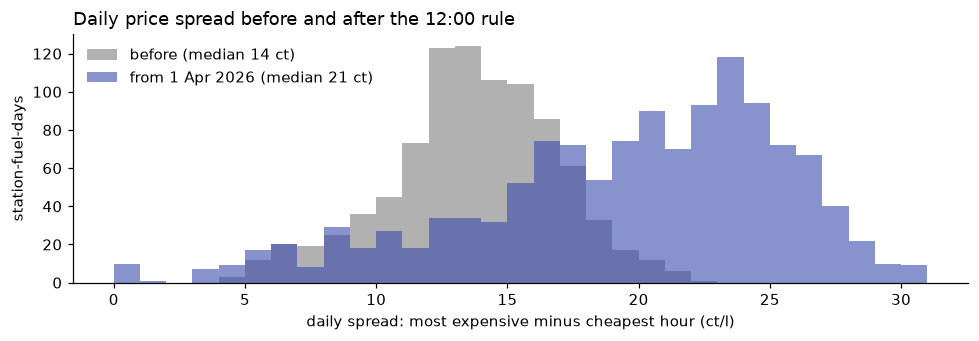

In [8]:
fig, ax = plt.subplots(figsize=(9, 3.2))
bins = np.arange(0, daily["spread_ct"].quantile(0.99) + 2, 1)
ax.hist(before, bins=bins, color=COLORS["before"], alpha=0.8, label=f"before (median {before.median():.0f} ct)")
ax.hist(after, bins=bins, color=COLORS["after"], alpha=0.6, label=f"from 1 Apr 2026 (median {after.median():.0f} ct)")
ax.set_xlabel("daily spread: most expensive minus cheapest hour (ct/l)")
ax.set_ylabel("station-fuel-days")
ax.set_title("Daily price spread before and after the 12:00 rule", loc="left")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(IMG / "daily_spread.png")
plt.show()

## 4. Is Sprint cheaper than Shell?

For each fuel and day the average price difference Shell minus Sprint is computed from the same
hours at both stations (a paired comparison). The Wilcoxon signed-rank test checks whether the
difference is centred on zero.

In [9]:
pairs = hourly.pivot_table(index=["fuel", "hour_utc", "local_date", "period"], columns="station",
                           values="price").dropna().reset_index()
pairs["shell_minus_sprint_ct"] = 100 * (pairs["shell"] - pairs["sprint"])

by_day = pairs.groupby(["fuel", "local_date", "period"])["shell_minus_sprint_ct"].mean().reset_index()
rows = []
for fuel, g in by_day.groupby("fuel"):
    w = stats.wilcoxon(g["shell_minus_sprint_ct"])
    rows.append({
        "fuel": fuel,
        "mean gap (ct)": round(g["shell_minus_sprint_ct"].mean(), 2),
        "days Sprint cheaper (%)": round(100 * (g["shell_minus_sprint_ct"] > 0).mean(), 1),
        "hours Sprint cheaper (%)": round(100 * (pairs.loc[pairs["fuel"] == fuel, "shell_minus_sprint_ct"] > 0).mean(), 1),
        "Wilcoxon p": f"{w.pvalue:.1e}",
    })
pd.DataFrame(rows)

,fuel,mean gap (ct),days Sprint cheaper (%),hours Sprint cheaper (%),Wilcoxon p
0,diesel,2.65,98.9,99.1,5.5e-57
1,e10,2.62,98.9,99.3,6.4e-60
2,e5,2.62,98.9,99.3,6.4e-60


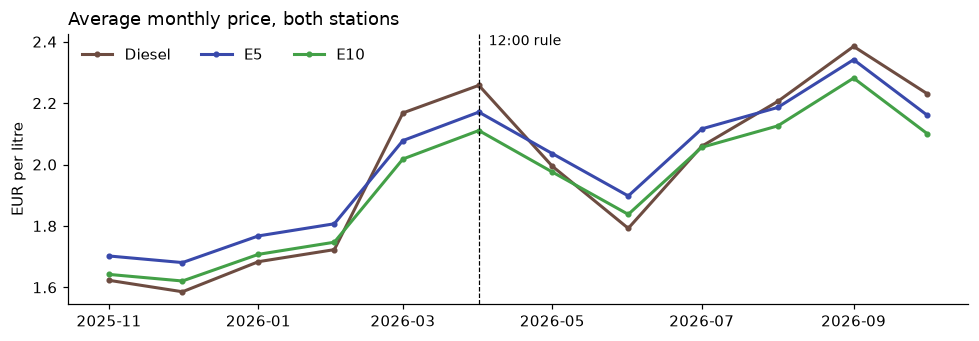

In [10]:
monthly = (hourly.assign(month=pd.to_datetime(hourly["local_date"]).dt.to_period("M").dt.to_timestamp())
           .groupby(["month", "fuel"])["price"].mean().unstack())

fig, ax = plt.subplots(figsize=(9, 3.2))
for fuel, color in [("diesel", "#6d4c41"), ("e5", "#3949ab"), ("e10", "#43a047")]:
    ax.plot(monthly.index, monthly[fuel], color=color, lw=2, marker="o", ms=3, label=fuel.upper() if fuel != "diesel" else "Diesel")
ax.axvline(pd.Timestamp("2026-04-01"), color="black", lw=0.8, ls="--")
ax.text(pd.Timestamp("2026-04-05"), ax.get_ylim()[1], "12:00 rule", va="top", fontsize=9)
ax.set_ylabel("EUR per litre")
ax.set_title("Average monthly price, both stations", loc="left")
ax.legend(frameon=False, ncol=3)
fig.tight_layout()
fig.savefig(IMG / "monthly_price.png")
plt.show()

## 5. Findings

The numbers in this section are printed by the cells above.

1. **The rule holds at both stations.** Before April, increases were spread over the day; afterwards almost
   all of them happen between 12:00 and 12:59.
2. **The cheapest time moved and the daily gap grew.** Before the rule fuel was most expensive in the morning
   and cheapest in the evening; after it the jump is at 12:00 and the cheapest time is just before noon.
   The daily spread between the most expensive and the cheapest hour became larger, also relative to the
   higher price level.
3. **Sprint is cheaper than Shell** in almost every hour, by a few cents per litre.

Limitations: two stations only, so the results describe these stations, not the market; consecutive days are
not independent, so the p-values are optimistic; the price level rose sharply from March 2026, which overlaps
with the rule; some days show no price change for more than 24 hours (station closed or no reports), and the
last known price is assumed to hold.